# Machine Learning - Niveau 3

## Apprentissage non supervisé : les k-moyennes

Dans les notebooks précédents, une réponse accompagnait chaque observation. L'[analyse des données bancaires](IA_ING_ML0_data_analysis.ipynb) préparait la cible `y`. Le [niveau 1](ML_1.ipynb) prédisait une souscription `yes` / `no`. Le [niveau 2](ML_2_svm_knn_random_forest.ipynb) prédisait l'une des sept couvertures forestières. Ce niveau-ci part d'une situation différente : **on dispose des caractéristiques `X`, et d'aucune étiquette.**

L'objectif est de découvrir des groupes d'observations proches. L'algorithme étudié est celui des **k-moyennes** (k-means) : il place `K` centres, affecte chaque point au centre le plus proche, puis déplace chaque centre vers la moyenne de son groupe, jusqu'à stabilisation.

Les images viennent de sources publiques (Wikimedia Commons et la documentation scikit-learn). Les jeux numériques viennent de générateurs et du jeu Wine, chargés sans Google Drive.

**Parcours** — les numéros sont ceux des sections.

| Section | Question |
|---|---|
| 1 | En quoi le non supervisé diffère-t-il du supervisé ? |
| 2 | À quoi ressemblent des groupes quand on cache les étiquettes ? |
| 3 | Quelles sont les deux étapes des k-moyennes ? |
| 4 | Pourquoi deux départs donnent-ils deux résultats ? |
| 5 | Pourquoi la standardisation change-t-elle les groupes ? |
| 6 | Quelles formes de nuages l'algorithme récupère-t-il ? |
| 7 | Quand un algorithme de densité fait-il mieux ? |
| 8 | Comment proposer un nombre de groupes `K` ? |
| 9 | Que signifie regrouper les pixels d'une photo ? |
| 10 | Des mesures chimiques rapprochent-elles les vins d'un même cépage ? |


## 1. Supervisé et non supervisé

![Points regroupés par proximité](https://upload.wikimedia.org/wikipedia/commons/thumb/c/c8/Cluster-2.svg/500px-Cluster-2.svg.png)

*Des points se rassemblent par proximité, sans nom de classe écrit à l'avance. Source : [Cluster-2.svg](https://commons.wikimedia.org/wiki/File:Cluster-2.svg), Wikimedia Commons.*

| | Apprentissage supervisé (niveaux 1 et 2) | Apprentissage non supervisé (ce notebook) |
|---|---|---|
| Entrée | Caractéristiques `X` et réponse `y` | Caractéristiques `X` seules |
| Question | Quelle étiquette prédire pour un nouvel exemple ? | Quels exemples se ressemblent ? |
| Exemples | Souscription bancaire, essence forestière | Segments de clients, couleurs d'une image, familles de mesures |
| Repère de qualité | Précision, rappel, F1, OA, mIoU, sur un jeu de test | Compacité des groupes, stabilité, et parfois un indice externe si une référence existe à part |

Un regroupement décrit une structure. Il ne démontre pas à lui seul une cause, ni une décision métier. Comme au niveau 1, le sens des groupes se juge avec le contexte : un groupe de pixels bleu peut être un lac, un ciel, ou les deux à la fois.


### Installer les dépendances et préparer les outils


In [1]:
%pip install -q scikit-learn matplotlib pillow


Note: you may need to restart the kernel to use updated packages.


In [2]:
import time
import urllib.request
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import load_wine, make_blobs, make_circles, make_moons
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


## 2. Un jeu à trois groupes, vu sans les étiquettes

On fabrique 500 points en deux dimensions, issus de trois groupes compacts. Le dessin de gauche est celui que l'algorithme reçoit : des positions, sans couleur de classe. Le dessin de droite recolore les points avec les groupes utilisés pour la simulation. Ces couleurs servent de corrigé pour comprendre le résultat. Elles ne sont pas fournies à l'algorithme.


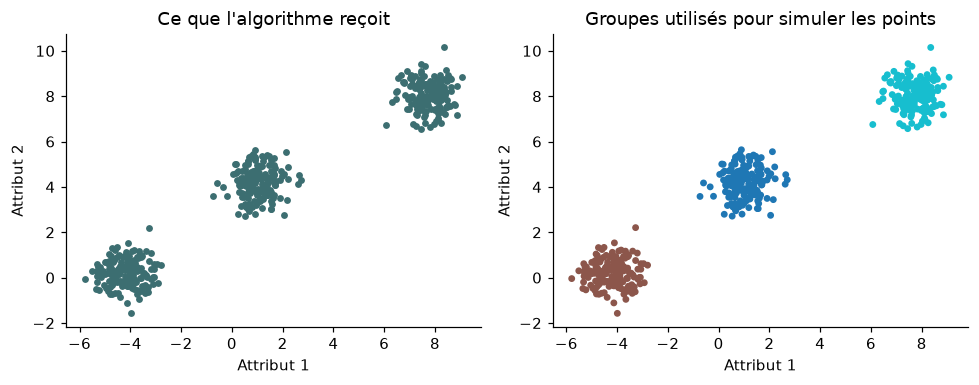

X a la forme (500, 2) : 500 observations, 2 attributs.


In [3]:
X_blobs, y_blobs = make_blobs(
    n_samples=500,
    centers=3,
    cluster_std=0.60,
    random_state=3,
)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].scatter(X_blobs[:, 0], X_blobs[:, 1], s=12, c="#3c6e71")
axes[0].set_title("Ce que l'algorithme reçoit")
axes[1].scatter(X_blobs[:, 0], X_blobs[:, 1], s=12, c=y_blobs, cmap="tab10")
axes[1].set_title("Groupes utilisés pour simuler les points")
for ax in axes:
    ax.set_xlabel("Attribut 1")
    ax.set_ylabel("Attribut 2")
fig.tight_layout()
plt.show()

print(f"X a la forme {X_blobs.shape} : {X_blobs.shape[0]} observations, {X_blobs.shape[1]} attributs.")


### Lire ces deux figures

Les trois paquets sont visibles à l'œil parce que le plan n'a que deux axes et que les groupes sont compacts. Avec davantage d'attributs, ce dessin n'existe plus : l'algorithme doit travailler à partir des distances. Le corrigé coloré reste de côté. S'en servir pendant le calcul reviendrait à refaire de l'apprentissage supervisé.


## 3. L'algorithme des k-moyennes

![Itérations des k-moyennes](https://upload.wikimedia.org/wikipedia/commons/e/ea/K-means_convergence.gif)

*Les centres (étoiles) et les affectations se mettent à jour jusqu'à se stabiliser. Source : [K-means convergence.gif](https://commons.wikimedia.org/wiki/File:K-means_convergence.gif), Wikimedia Commons.*

On choisit un nombre de groupes `K`. Puis on répète deux gestes.

**Affectation.** Chaque observation rejoint le centre le plus proche :

$$
c_i = \arg\min_{j \in \{1,\ldots,K\}} \| x_i - \mu_j \|
$$

**Mise à jour.** Chaque centre devient la moyenne des observations de son groupe :

$$
\mu_j = \frac{1}{|C_j|} \sum_{x_i \in C_j} x_i
$$

On s'arrête quand les centres bougent peu, ou après un nombre maximal d'itérations. L'**inertie** résume la compacité obtenue : c'est la somme des carrés des distances de chaque point à son centre. Elle diminue à chaque mise à jour réussie. Une inertie faible indique des groupes serrés autour de leurs centres. Elle dépend de `K` et de l'échelle des axes, donc on ne la compare pas d'un jeu de données à un autre sans précaution.

La **standardisation** met chaque attribut à moyenne nulle et écart-type 1, comme le `StandardScaler` des niveaux 1 et 2 :

$$
z_{i,j} = \frac{x_{i,j} - \bar x_j}{s_j}
$$

Les fonctions ci-dessous suivent ces étapes et acceptent un nombre quelconque d'attributs : la distance est calculée sur toutes les colonnes, pas seulement sur deux.


In [4]:
def standardiser(X):
    """Ramène chaque colonne à une moyenne nulle et un écart-type de 1."""
    moyenne = X.mean(axis=0)
    ecart_type = X.std(axis=0)
    ecart_type = np.where(ecart_type < 1e-12, 1.0, ecart_type)
    return (X - moyenne) / ecart_type, moyenne, ecart_type


def centres_initiaux(X, k, graine):
    """Choisit k observations comme centres de départ."""
    generateur = np.random.default_rng(graine)
    indices = generateur.choice(X.shape[0], size=k, replace=False)
    return X[indices].copy(), generateur


def distances_aux_centres(X, centres):
    """Distance euclidienne de chaque observation à chaque centre.

    La boucle parcourt les centres. Chaque observation peut avoir autant
    d'attributs que de colonnes dans X.
    """
    distances = np.empty((X.shape[0], centres.shape[0]))
    for j, centre in enumerate(centres):
        ecarts = X - centre
        distances[:, j] = np.sqrt(np.sum(ecarts ** 2, axis=1))
    return distances


def affecter(distances):
    """Indice du centre le plus proche pour chaque observation."""
    return np.argmin(distances, axis=1)


def nouveaux_centres(X, etiquettes, centres, generateur):
    """Moyenne de chaque groupe. Un groupe vide est relancé sur une observation."""
    centres_mis_a_jour = centres.copy()
    for indice in range(centres.shape[0]):
        membres = etiquettes == indice
        if np.any(membres):
            centres_mis_a_jour[indice] = X[membres].mean(axis=0)
        else:
            centres_mis_a_jour[indice] = X[generateur.integers(0, X.shape[0])]
    return centres_mis_a_jour


def k_moyennes(X, k, epsilon=1e-4, max_iterations=40, standardiser_donnees=True, graine=0, memoriser=False):
    """Regroupe les lignes de X en k groupes et retourne le détail de l'exécution."""
    X = np.asarray(X, dtype=float)
    if standardiser_donnees:
        X_travail, _, _ = standardiser(X)
    else:
        X_travail = X.copy()

    centres, generateur = centres_initiaux(X_travail, k, graine)
    etiquettes = np.zeros(X_travail.shape[0], dtype=int)
    historique = []
    iterations = 0

    for iteration in range(max_iterations):
        iterations = iteration + 1
        etiquettes = affecter(distances_aux_centres(X_travail, centres))
        if memoriser:
            historique.append(
                {
                    "iteration": iteration,
                    "etiquettes": etiquettes.copy(),
                    "centres": centres.copy(),
                }
            )
        candidats = nouveaux_centres(X_travail, etiquettes, centres, generateur)
        deplacement = float(np.linalg.norm(candidats - centres, axis=1).max())
        centres = candidats
        if deplacement <= epsilon:
            break

    etiquettes = affecter(distances_aux_centres(X_travail, centres))
    inertie = float(np.sum((X_travail - centres[etiquettes]) ** 2))
    return {
        "etiquettes": etiquettes,
        "centres": centres,
        "X": X_travail,
        "inertie": inertie,
        "iterations": iterations,
        "historique": historique,
    }


def indice_externe(etiquettes_reference, etiquettes_predites):
    """ARI si une référence existe, sinon une valeur manquante."""
    if etiquettes_reference is None:
        return np.nan
    return float(adjusted_rand_score(etiquettes_reference, etiquettes_predites))


## 4. Deux départs, deux résultats

Les centres de départ sont des observations tirées au hasard. Sur les trois groupes compacts, une graine peut tomber sur un minimum local : deux centres se partagent le même paquet, et le troisième paquet reste collé à un voisin. Une autre graine place un centre dans chaque paquet et l'inertie chute.

L'**indice de Rand ajusté** (ARI) compare les groupes trouvés au corrigé de la simulation. Les numéros de groupes n'ont pas besoin de coïncider : seul le découpage compte.

- **1** : les deux partitions sont les mêmes.
- **0** : la ressemblance est celle du hasard.
- **Une valeur un peu négative**, comme −0,001 ou −0,002, reste un accord nul. L'indice est ajusté pour valoir 0 en moyenne quand on groupe au hasard ; un tirage peut donc passer légèrement sous 0. Ce n'est pas une erreur de calcul.

Dans une application réelle, ce corrigé est absent : l'ARI sert ici à comprendre l'algorithme.


Graine 0 : 13 itérations, inertie 238.3, ARI 0.441, effectifs [333, 84, 83]
Graine 1 : 4 itérations, inertie 25.3, ARI 1.000, effectifs [167, 166, 167]


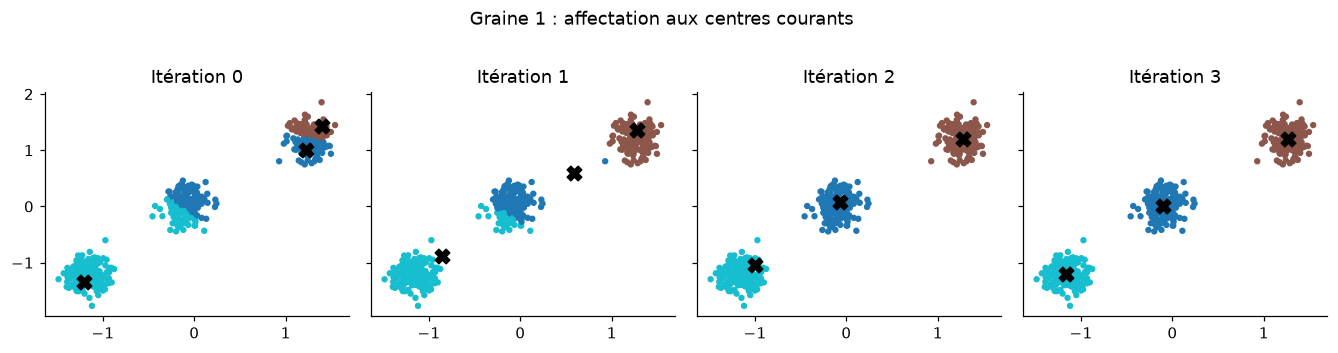

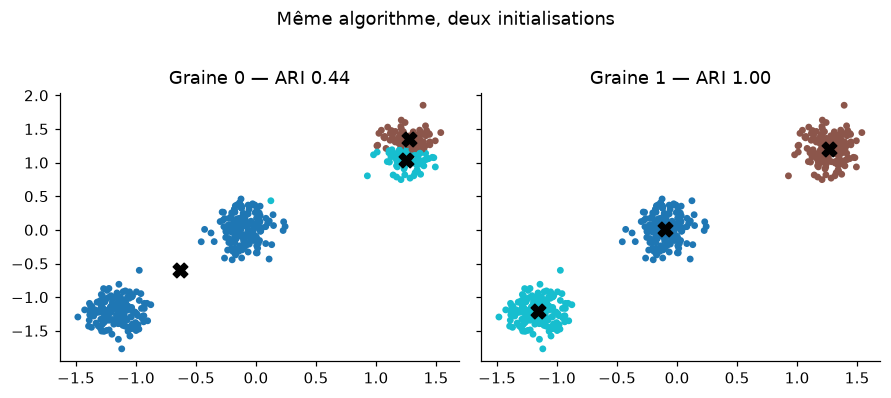

In [5]:
comparaison_graines = {}
for graine in (0, 1):
    resultat = k_moyennes(X_blobs, k=3, graine=graine, standardiser_donnees=True, memoriser=True)
    ari = indice_externe(y_blobs, resultat["etiquettes"])
    comparaison_graines[graine] = resultat
    effectifs = np.bincount(resultat["etiquettes"], minlength=3)
    print(
        f"Graine {graine} : {resultat['iterations']} itérations, "
        f"inertie {resultat['inertie']:.1f}, ARI {ari:.3f}, effectifs {effectifs.tolist()}"
    )

resultat_stable = comparaison_graines[1]
etapes = resultat_stable["historique"]
fig, axes = plt.subplots(1, len(etapes), figsize=(3.1 * len(etapes), 3.1), sharex=True, sharey=True)
if len(etapes) == 1:
    axes = [axes]
for ax, etape in zip(axes, etapes):
    ax.scatter(resultat_stable["X"][:, 0], resultat_stable["X"][:, 1], c=etape["etiquettes"], s=10, cmap="tab10")
    ax.scatter(etape["centres"][:, 0], etape["centres"][:, 1], c="black", marker="X", s=90)
    ax.set_title(f"Itération {etape['iteration']}")
fig.suptitle("Graine 1 : affectation aux centres courants", y=1.02)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.5), sharex=True, sharey=True)
for ax, graine in zip(axes, (0, 1)):
    resultat = comparaison_graines[graine]
    ari = indice_externe(y_blobs, resultat["etiquettes"])
    ax.scatter(resultat["X"][:, 0], resultat["X"][:, 1], c=resultat["etiquettes"], s=12, cmap="tab10")
    ax.scatter(resultat["centres"][:, 0], resultat["centres"][:, 1], c="black", marker="X", s=90)
    ax.set_title(f"Graine {graine} — ARI {ari:.2f}")
fig.suptitle("Même algorithme, deux initialisations", y=1.02)
fig.tight_layout()
plt.show()


### Interpréter l'initialisation

Avec la graine 1, l'inertie descend à **25,3** et l'ARI vaut **1,0** : chaque paquet simulé forme un groupe, avec des effectifs d'environ 167 points. Les croix noires se placent au milieu de ces paquets en quelques itérations.

Avec la graine 0, l'inertie reste à **238** et l'ARI tombe à **0,44**. Les effectifs 333, 84 et 83 montrent qu'un groupe trouvé a absorbé deux paquets simulés. L'algorithme s'est stabilisé : continuer les itérations ne répare pas ce départ. C'est un minimum local.

Les implémentations de bibliothèque, dont `sklearn.cluster.KMeans`, relancent plusieurs initialisations (souvent avec l'initialisation k-means++) et conservent la plus faible inertie. Le code de ce notebook garde une seule graine à la fois, justement pour rendre ce phénomène visible.


## 5. La standardisation change la géométrie

On construit deux groupes séparés sur un **signal de faible amplitude** (écarts d'environ 0 et 1). Un second attribut est un **bruit de forte amplitude**, de même loi dans les deux groupes (écart-type 40). La distance euclidienne additionne les carrés des écarts sur tous les axes : sans standardisation, le bruit écrase le signal.

Cette situation est la même que celle des variables bancaires ou forestières des notebooks précédents : un montant en euros et un indicateur binaire ne vivent pas sur la même échelle. `StandardScaler` était alors dans le pipeline. Ici, il joue le même rôle avant le calcul des distances.


Sans standardisation : inertie 306317.6, ARI -0.001
Avec standardisation : inertie 511.9, ARI 1.000


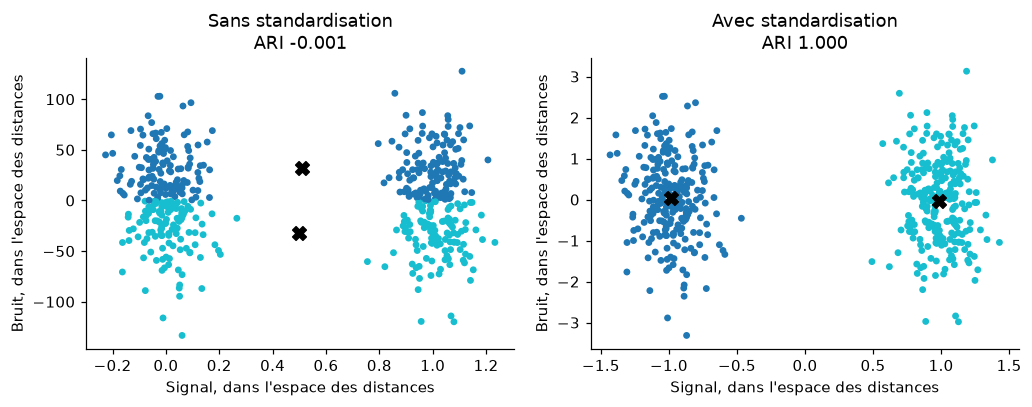

In [6]:
generateur = np.random.default_rng(3)
n_par_groupe = 250
signal = np.concatenate(
    [
        generateur.normal(0.0, 0.08, n_par_groupe),
        generateur.normal(1.0, 0.08, n_par_groupe),
    ]
)
bruit = generateur.normal(0.0, 40.0, n_par_groupe * 2)
X_echelles = np.column_stack([signal, bruit])
y_echelles = np.array([0] * n_par_groupe + [1] * n_par_groupe)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for ax, standardiser_donnees, titre in (
    (axes[0], False, "Sans standardisation"),
    (axes[1], True, "Avec standardisation"),
):
    resultat = k_moyennes(
        X_echelles,
        k=2,
        graine=0,
        standardiser_donnees=standardiser_donnees,
    )
    ari = indice_externe(y_echelles, resultat["etiquettes"])
    ax.scatter(resultat["X"][:, 0], resultat["X"][:, 1], c=resultat["etiquettes"], s=12, cmap="tab10")
    ax.scatter(resultat["centres"][:, 0], resultat["centres"][:, 1], c="black", marker="X", s=80)
    ax.set_title(f"{titre}\nARI {ari:.3f}")
    ax.set_xlabel("Signal, dans l'espace des distances")
    ax.set_ylabel("Bruit, dans l'espace des distances")
    print(f"{titre} : inertie {resultat['inertie']:.1f}, ARI {ari:.3f}")

fig.tight_layout()
plt.show()


### Interpréter les échelles

Sans standardisation, l'ARI vaut **−0,001** : c'est le niveau du hasard, pas une panne du calcul. Sur la figure de gauche, chaque nuage du signal contient les deux couleurs : les centres se sont séparés le long de l'axe bruyant, celui dont les valeurs parcourent des dizaines d'unités.

Avec standardisation, l'ARI vaut **1,0**. Les deux groupes du signal redeviennent les deux groupes trouvés. Les axes du graphique de droite sont ceux dans lesquels les distances ont été calculées : le signal et le bruit y ont le même poids.

La standardisation est donc un choix de géométrie. Elle est adaptée quand les unités sont arbitraires. Elle est inutile, voire gênante, quand les axes ont déjà le même sens et la même unité, comme les canaux rouge, vert et bleu d'une image, traités plus loin.


## 6. Quelles formes les k-moyennes retrouvent-elles ?

Chaque observation rejoint le centre le plus proche. La frontière entre deux centres est l'ensemble des points situés à égale distance des deux. Ce découpage réussit quand les groupes sont des paquets compacts, de taille comparable. Il rate les anneaux, les croissants et, plus largement, les groupes qui ne forment pas une boule.

La figure qui suit montre six formes, avec la graine 1. On lit **une ligne de gauche à droite** : le corrigé simulé, puis les k-moyennes avec standardisation, puis sans. Les échelles différentes n'y figurent pas : la section 5 les a déjà montrées seules.

D'autres algorithmes, sur les mêmes familles de nuages, sont comparés dans la [documentation scikit-learn](https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_comparison.html).


Jeu                    ARI avec std ARI sans std
Blobs compacts                1.000        1.000
Cercles imbriqués            -0.002       -0.002
Croissants                    0.483        0.253
Groupes allongés              0.578        0.558
Variances inégales            0.740        0.787
Nuage uniforme                    —            —


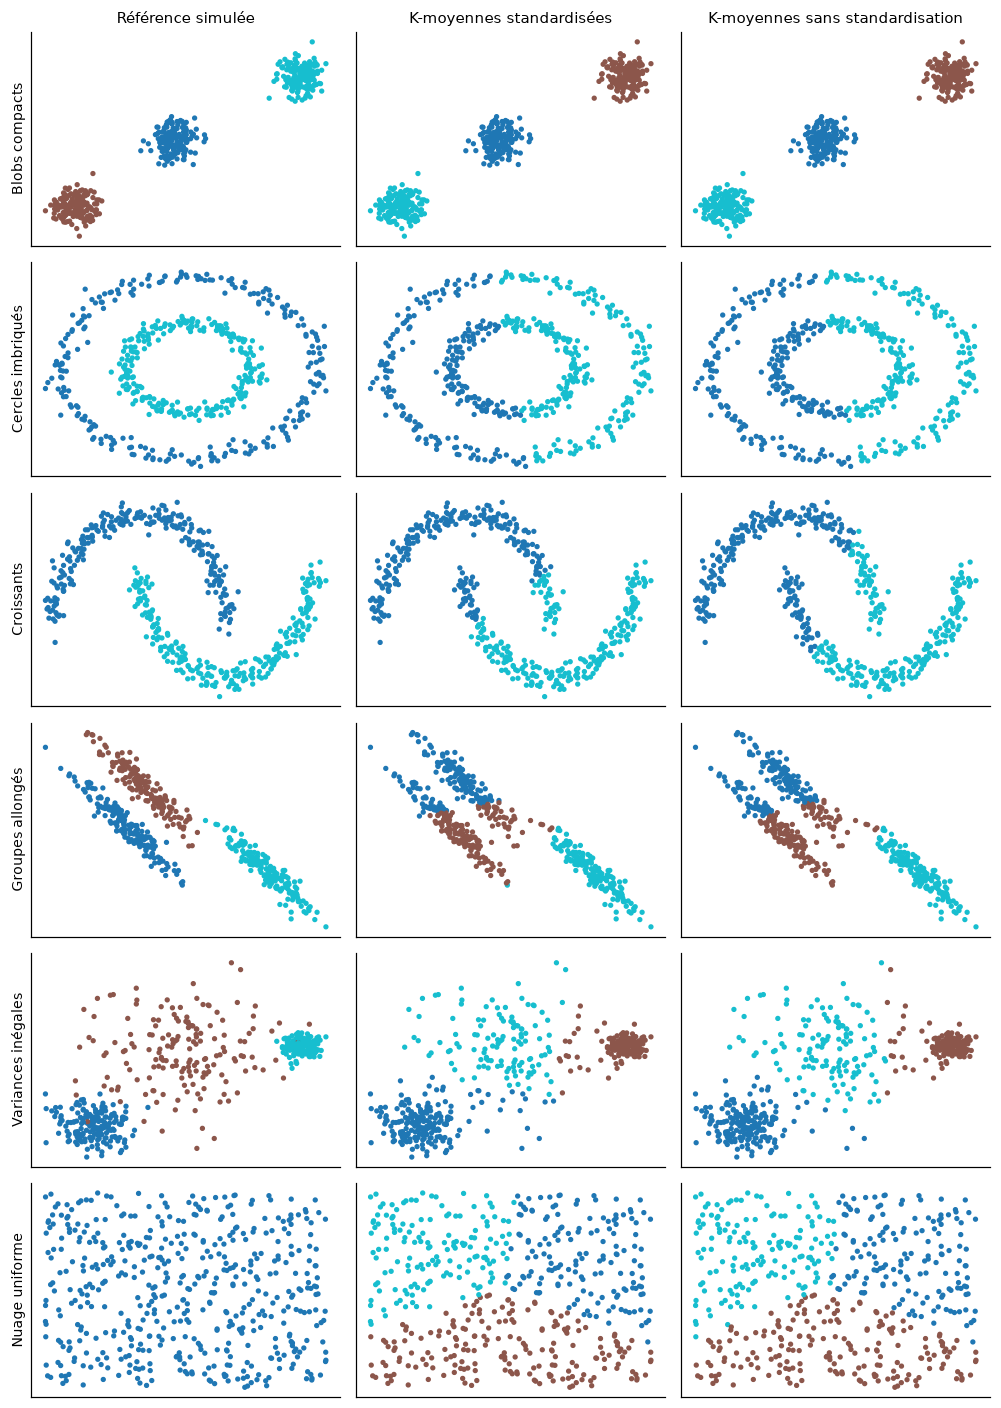

In [7]:
def jeux_de_formes(n_points=500, graine=3):
    """Six nuages utilisés pour voir les limites géométriques des k-moyennes."""
    generateur = np.random.default_rng(graine)
    jeux = []

    X, y = make_blobs(n_samples=n_points, centers=3, cluster_std=0.60, random_state=graine)
    jeux.append(("Blobs compacts", X, y, 3))

    X, y = make_circles(n_samples=n_points, factor=0.5, noise=0.05, random_state=graine)
    jeux.append(("Cercles imbriqués", X, y, 2))

    X, y = make_moons(n_samples=n_points, noise=0.06, random_state=graine)
    jeux.append(("Croissants", X, y, 2))

    X, y = make_blobs(n_samples=n_points, centers=3, random_state=170)
    X = X @ np.array([[0.6, -0.6], [-0.4, 0.8]])
    jeux.append(("Groupes allongés", X, y, 3))

    X, y = make_blobs(
        n_samples=n_points,
        centers=3,
        cluster_std=[1.0, 2.5, 0.5],
        random_state=170,
    )
    jeux.append(("Variances inégales", X, y, 3))

    X = generateur.uniform(0, 1, size=(n_points, 2))
    jeux.append(("Nuage uniforme", X, None, 3))
    return jeux


jeux = jeux_de_formes()
fig, axes = plt.subplots(len(jeux), 3, figsize=(9.2, 2.15 * len(jeux)))
def formater_ari(valeur):
    if valeur is None or (isinstance(valeur, float) and np.isnan(valeur)):
        return f"{'—':>12}"
    return f"{valeur:12.3f}"

print(f"{'Jeu':22} {'ARI avec std':>12} {'ARI sans std':>12}")

for ligne, (nom, X, y, k) in enumerate(jeux):
    X_affiche, _, _ = standardiser(X)
    avec = k_moyennes(X, k=k, graine=1, standardiser_donnees=True)
    sans = k_moyennes(X, k=k, graine=1, standardiser_donnees=False)
    ari_avec = indice_externe(y, avec["etiquettes"])
    ari_sans = indice_externe(y, sans["etiquettes"])
    print(f"{nom:22} {formater_ari(ari_avec)} {formater_ari(ari_sans)}")

    panneaux = (
        (y if y is not None else np.zeros(len(X_affiche)), "Référence simulée"),
        (avec["etiquettes"], "K-moyennes standardisées"),
        (sans["etiquettes"], "K-moyennes sans standardisation"),
    )
    for colonne, (couleurs, titre) in enumerate(panneaux):
        ax = axes[ligne, colonne]
        ax.scatter(X_affiche[:, 0], X_affiche[:, 1], c=couleurs, s=6, cmap="tab10")
        ax.set_xticks([])
        ax.set_yticks([])
        if ligne == 0:
            ax.set_title(titre, fontsize=10)
        if colonne == 0:
            ax.set_ylabel(nom, fontsize=9)

fig.tight_layout()
plt.show()


### Lire la galerie

Les points sont dessinés après standardisation, pour que les formes soient comparables. L'ARI de la deuxième colonne est celui de la version standardisée.

- **Blobs compacts.** ARI **1,0**. Trois paquets ronds, de même taille. La graine 1 évite le minimum local de la section 4.
- **Cercles imbriqués.** ARI **−0,002**, donc le hasard. La frontière coupe les deux anneaux. Un anneau n'a pas un centre unique.
- **Croissants.** ARI **0,483** avec standardisation, **0,253** sans. Une partie de chaque croissant est récupérée, l'autre est collée au voisin. La forme réelle est courbe.
- **Groupes allongés.** ARI environ **0,58**. Un point au bout d'un groupe allongé peut être plus proche du centre d'un autre groupe que du sien.
- **Variances inégales.** ARI **0,740**. Les deux groupes serrés sont retrouvés. Le grand nuage diffus est coupé en deux.
- **Nuage uniforme.** Pas de corrigé, et pourtant trois régions apparaissent. Obtenir `K` groupes ne prouve pas que `K` groupes existaient.

Sur les cercles, les groupes trouvés sont compacts autour de leurs centres, et ils mélangent quand même les deux anneaux. Une inertie faible ne garantit pas d'avoir retrouvé le phénomène étudié.


## 7. Une autre famille : la densité

Quand la forme n'est pas un paquet autour d'un centre, un algorithme fondé sur la densité peut suivre le croissant. `DBSCAN` relie les points qui ont assez de voisins dans un rayon `eps`. Il n'a pas besoin qu'on lui donne `K`. Les points isolés peuvent rester marqués comme du bruit (`étiquette -1`).

`eps` est une distance dans l'espace utilisé. Ici les croissants sont standardisés, donc `eps=0,3` signifie 0,3 écart-type. Cette valeur est choisie pour ce dessin ; un autre jeu demande un autre rayon.


K-moyennes (bibliothèque, 10 départs) : ARI 0.483
DBSCAN : ARI 0.996, points de bruit 1


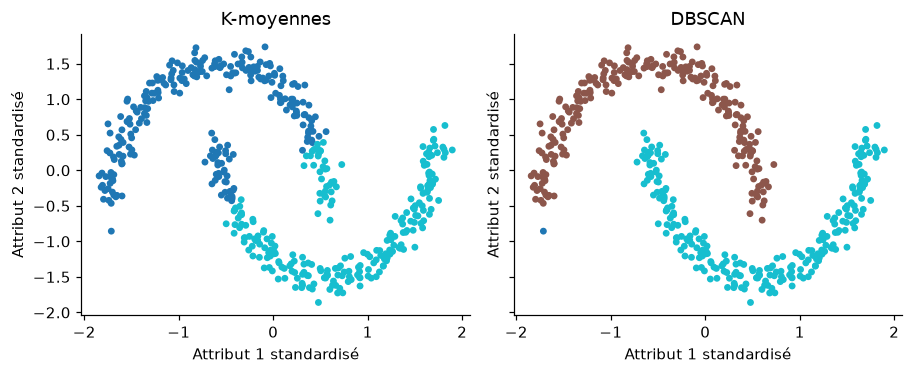

In [8]:
X_croissants, y_croissants = make_moons(n_samples=500, noise=0.06, random_state=3)
X_croissants_std = StandardScaler().fit_transform(X_croissants)

etiquettes_centres = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X_croissants_std)
etiquettes_densite = DBSCAN(eps=0.3, min_samples=5).fit_predict(X_croissants_std)

print(f"K-moyennes (bibliothèque, 10 départs) : ARI {adjusted_rand_score(y_croissants, etiquettes_centres):.3f}")
print(
    f"DBSCAN : ARI {adjusted_rand_score(y_croissants, etiquettes_densite):.3f}, "
    f"points de bruit {(etiquettes_densite == -1).sum()}"
)

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.5), sharex=True, sharey=True)
axes[0].scatter(X_croissants_std[:, 0], X_croissants_std[:, 1], c=etiquettes_centres, s=12, cmap="tab10")
axes[0].set_title("K-moyennes")
axes[1].scatter(X_croissants_std[:, 0], X_croissants_std[:, 1], c=etiquettes_densite, s=12, cmap="tab10")
axes[1].set_title("DBSCAN")
for ax in axes:
    ax.set_xlabel("Attribut 1 standardisé")
    ax.set_ylabel("Attribut 2 standardisé")
fig.tight_layout()
plt.show()


### Interpréter les croissants

Les k-moyennes de scikit-learn, même avec 10 départs, obtiennent un ARI de **0,483** : relancer l'initialisation améliore la stabilité, pas la capacité à suivre une forme courbe.

DBSCAN obtient un ARI de **0,996** et laisse **1 point** en bruit. Les deux croissants sont chacun une zone dense. Le bon outil dépend de la forme que l'on suppose aux groupes. DBSCAN demande en échange de régler `eps` et `min_samples`, et il gère mal des groupes de densités très différentes.


## 8. Choisir le nombre de groupes

Sans corrigé, deux courbes aident à proposer `K`.

L'**inertie** baisse quand on ajoute des centres : avec assez de centres, chaque point peut se rapprocher du sien. On cherche un **coude**, c'est-à-dire un `K` après lequel la baisse devient petite.

La **silhouette** moyenne compare, pour chaque point, la distance aux membres de son groupe et la distance au groupe voisin le plus proche. Elle est proche de 1 quand les groupes sont compacts et séparés, et proche de 0 quand les frontières sont floues. On la calcule pour `K ≥ 2`.

Sur les blobs, ces deux courbes peuvent être confrontées à l'ARI, uniquement parce que la simulation fournit un corrigé. `KMeans` est lancé avec `n_init=10` pour écarter le mauvais départ de la graine unique.


K=1  inertie= 1000.0  silhouette=     —  ARI=0.000
K=2  inertie=  242.2  silhouette= 0.694  ARI=0.569
K=3  inertie=   25.3  silhouette= 0.829  ARI=1.000


K=4  inertie=   20.8  silhouette= 0.684  ARI=0.868
K=5  inertie=   16.9  silhouette= 0.538  ARI=0.728
K=6  inertie=   13.4  silhouette= 0.394  ARI=0.573


K=7  inertie=   12.2  silhouette= 0.371  ARI=0.525
K=8  inertie=   11.0  silhouette= 0.368  ARI=0.469


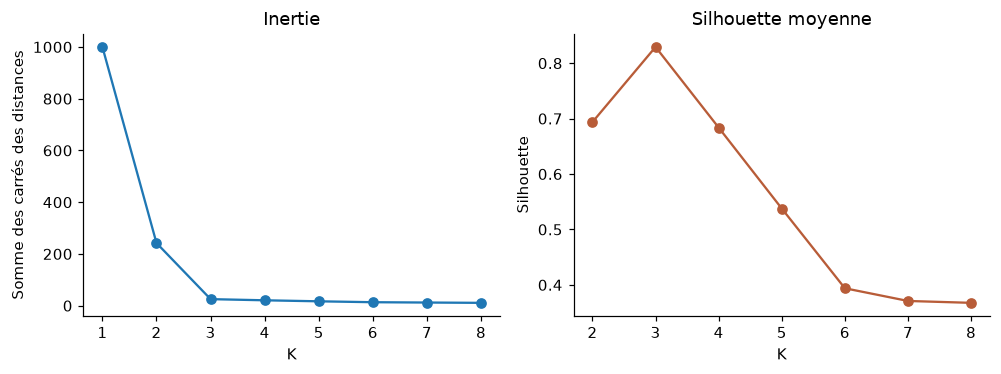

In [9]:
X_choix = StandardScaler().fit_transform(X_blobs)
valeurs_k = list(range(1, 9))
inerties = []
silhouettes = []
aris = []

for k in valeurs_k:
    modele = KMeans(n_clusters=k, n_init=10, random_state=0)
    etiquettes = modele.fit_predict(X_choix)
    inerties.append(modele.inertia_)
    silhouettes.append(np.nan if k == 1 else silhouette_score(X_choix, etiquettes))
    aris.append(adjusted_rand_score(y_blobs, etiquettes))
    silhouette_texte = "—" if k == 1 else f"{silhouettes[-1]:.3f}"
    print(f"K={k}  inertie={inerties[-1]:7.1f}  silhouette={silhouette_texte:>6}  ARI={aris[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.5))
axes[0].plot(valeurs_k, inerties, marker="o")
axes[0].set_title("Inertie")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Somme des carrés des distances")
axes[1].plot(valeurs_k[1:], silhouettes[1:], marker="o", color="#b85c38")
axes[1].set_title("Silhouette moyenne")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette")
fig.tight_layout()
plt.show()


### Interpréter le choix de K sur les blobs

L'inertie passe de **1000** (`K=1`) à **242** (`K=2`) puis à **25,3** (`K=3`). Ensuite la baisse est faible : **20,8** pour `K=4`. Le coude est à **3**.

La silhouette est maximale à `K=3` (**0,829**), devant `K=2` (0,694) et `K=4` (0,684). L'ARI, disponible ici grâce au corrigé, vaut **1,0** pour ce même `K`. Les trois repères se rejoignent parce que les groupes sont compacts et séparés. La section sur les vins montrera un cas réel où le coude est beaucoup moins net.


## 9. Regrouper les couleurs d'une photographie

Chaque pixel est une observation à trois attributs : rouge, vert et bleu, déjà mesurés de 0 à 255. Ces trois axes ont la même unité, donc on **ne standardise pas**. Les k-moyennes cherchent alors une palette de `K` couleurs. Remplacer chaque pixel par la couleur de son centre produit une image quantifiée.

Ce regroupement suit les couleurs. Il ne détecte pas des objets : un lac et un ciel du même bleu peuvent partager un groupe, et un même rocher peut être coupé en deux si son ombre change la teinte.

Les photos sont téléchargées depuis Wikimedia Commons, puis réduites vers 180 pixels de large pour garder le calcul lisible. Le principe est identique sur une image en pleine résolution.

- Paysage du lac d'Arnisee : [fichier Commons](https://commons.wikimedia.org/wiki/File:Landscape_Arnisee-region.JPG)
- Coucher de soleil : [fichier Commons](https://commons.wikimedia.org/wiki/File:Sunset_2007-1.jpg)


In [10]:
PHOTOS = {
    "Paysage": "https://upload.wikimedia.org/wikipedia/commons/thumb/1/14/Landscape_Arnisee-region.JPG/500px-Landscape_Arnisee-region.JPG",
    "Coucher de soleil": "https://upload.wikimedia.org/wikipedia/commons/thumb/5/58/Sunset_2007-1.jpg/500px-Sunset_2007-1.jpg",
}


def telecharger_image(url, essais=3):
    """Télécharge une image RGB. Plusieurs essais limitent les refus temporaires du serveur."""
    derniere_erreur = None
    for essai in range(essais):
        try:
            requete = urllib.request.Request(
                url,
                headers={"User-Agent": "ML-niveau-3-notebook/1.0 (educational)"},
            )
            with urllib.request.urlopen(requete, timeout=60) as reponse:
                return np.asarray(Image.open(BytesIO(reponse.read())).convert("RGB"))
        except Exception as erreur:
            derniere_erreur = erreur
            time.sleep(1.5 * (essai + 1))
    raise RuntimeError(f"Téléchargement impossible pour {url}") from derniere_erreur


def reduire(image, largeur=180):
    hauteur, largeur_origine = image.shape[:2]
    nouvelle_hauteur = max(1, int(round(hauteur * largeur / largeur_origine)))
    reduite = Image.fromarray(image).resize((largeur, nouvelle_hauteur), Image.Resampling.LANCZOS)
    return np.asarray(reduite)


def quantifier_couleurs(image, k, graine=1):
    """Remplace chaque pixel par le centre de couleur le plus proche."""
    pixels = image.reshape(-1, 3).astype(float)
    resultat = k_moyennes(
        pixels,
        k=k,
        graine=graine,
        standardiser_donnees=False,
        memoriser=False,
        max_iterations=100,
    )
    reconstitue = resultat["centres"][resultat["etiquettes"]].reshape(image.shape)
    reconstitue = np.clip(np.rint(reconstitue), 0, 255).astype(np.uint8)
    return resultat, reconstitue


images = {nom: reduire(telecharger_image(url)) for nom, url in PHOTOS.items()}
for nom, image in images.items():
    print(f"{nom} : {image.shape[1]} × {image.shape[0]} pixels, {image.shape[2]} canaux")


Paysage : 180 × 120 pixels, 3 canaux
Coucher de soleil : 180 × 128 pixels, 3 canaux


Paysage, K=3 : 17 itérations, inertie 27151044


Paysage, K=5 : 28 itérations, inertie 16505533


Paysage, K=8 : 42 itérations, inertie 8368100


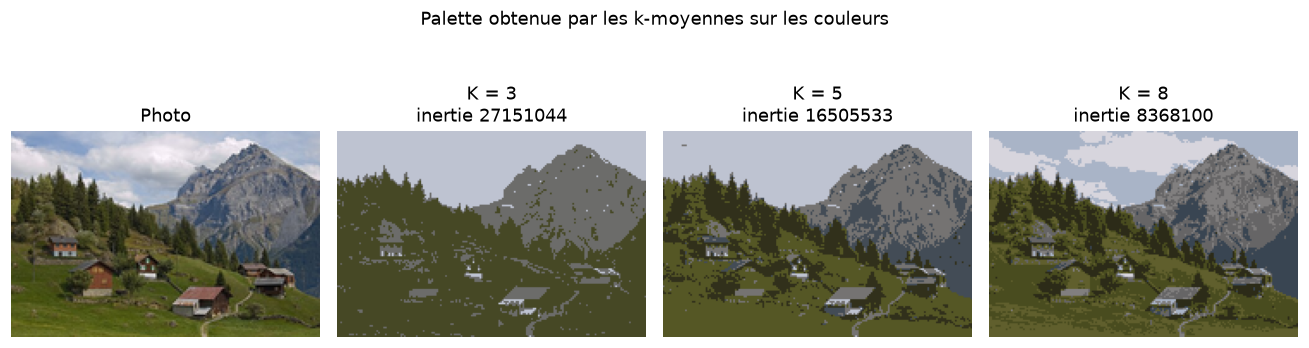

In [11]:
paysage = images["Paysage"]
choix_k = (3, 5, 8)
fig, axes = plt.subplots(1, 1 + len(choix_k), figsize=(12, 3.4))
axes[0].imshow(paysage)
axes[0].set_title("Photo")
axes[0].axis("off")

for ax, k in zip(axes[1:], choix_k):
    resultat, reconstitue = quantifier_couleurs(paysage, k=k, graine=1)
    ax.imshow(reconstitue)
    ax.set_title(f"K = {k}\ninertie {resultat['inertie']:.0f}")
    ax.axis("off")
    print(f"Paysage, K={k} : {resultat['iterations']} itérations, inertie {resultat['inertie']:.0f}")

fig.suptitle("Palette obtenue par les k-moyennes sur les couleurs", y=1.05)
fig.tight_layout()
plt.show()


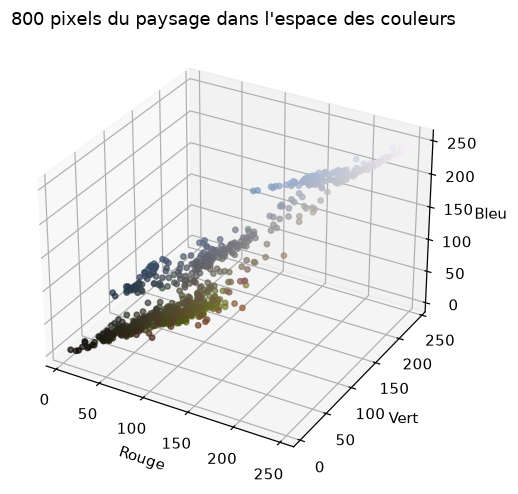

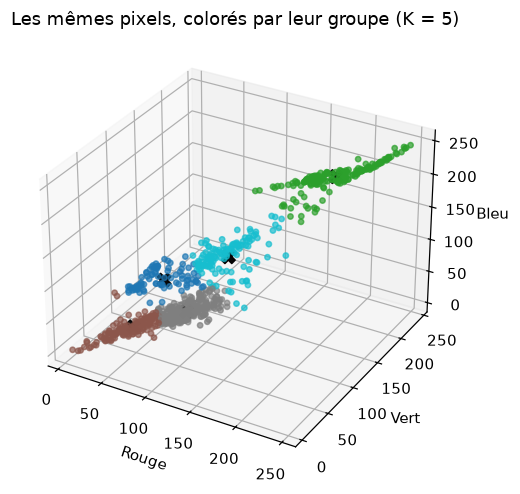

In [12]:
resultat_nuage, reconstitue_nuage = quantifier_couleurs(paysage, k=5, graine=1)
pixels = paysage.reshape(-1, 3)
generateur = np.random.default_rng(0)
echantillon = generateur.choice(pixels.shape[0], size=800, replace=False)

fig = plt.figure(figsize=(7.2, 5.2))
ax = fig.add_subplot(111, projection="3d")
couleurs_points = pixels[echantillon] / 255.0
ax.scatter(
    pixels[echantillon, 0],
    pixels[echantillon, 1],
    pixels[echantillon, 2],
    c=couleurs_points,
    s=12,
    alpha=0.85,
)
ax.set_xlabel("Rouge")
ax.set_ylabel("Vert")
ax.set_zlabel("Bleu")
ax.set_title("800 pixels du paysage dans l'espace des couleurs")
plt.show()

fig = plt.figure(figsize=(7.2, 5.2))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(
    pixels[echantillon, 0],
    pixels[echantillon, 1],
    pixels[echantillon, 2],
    c=resultat_nuage["etiquettes"][echantillon],
    cmap="tab10",
    s=12,
    alpha=0.85,
)
ax.scatter(
    resultat_nuage["centres"][:, 0],
    resultat_nuage["centres"][:, 1],
    resultat_nuage["centres"][:, 2],
    c="black",
    marker="X",
    s=80,
)
ax.set_xlabel("Rouge")
ax.set_ylabel("Vert")
ax.set_zlabel("Bleu")
ax.set_title("Les mêmes pixels, colorés par leur groupe (K = 5)")
plt.show()


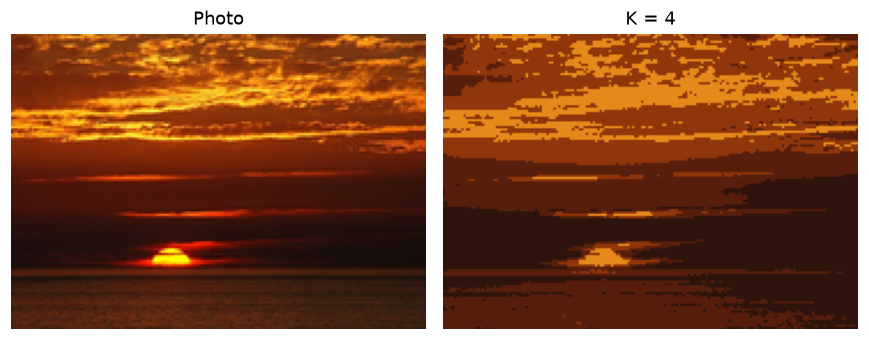

In [13]:
coucher = images["Coucher de soleil"]
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
axes[0].imshow(coucher)
axes[0].set_title("Photo")
axes[0].axis("off")
_, reconstitue = quantifier_couleurs(coucher, k=4, graine=1)
axes[1].imshow(reconstitue)
axes[1].set_title("K = 4")
axes[1].axis("off")
fig.tight_layout()
plt.show()


### Interpréter les images

Dans l'espace rouge-vert-bleu, les pixels clairs du ciel et de la neige s'alignent vers les fortes valeurs, et la végétation reste dans les valeurs sombres, côté vert. Avec `K=5`, les croix se placent dans ces concentrations. L'image reconstituée remplace chaque pixel par la couleur de son centre.

`K=3` suffit aux grandes masses : roche et ciel dans un gris, forêt en vert sombre, prairie en vert plus clair. Les chalets se fondent dans la prairie. L'inertie vaut alors environ **27 millions**. À `K=5`, le ciel se distingue mieux de la paroi et l'inertie descend vers **16,5 millions**. À `K=8`, les nuages, la neige et les façades retrouvent des teintes propres, et l'inertie descend vers **8,4 millions**. Le gain visuel ralentit : ajouter des couleurs serre les pixels autour des centres, sans créer de nouveaux objets.

Le coucher de soleil, avec `K=4`, sépare le disque solaire, les bandes orangées du ciel et la mer sombre. Deux régions éloignées dans la photo reçoivent la même teinte lorsque leurs pixels sont proches dans l'espace RGB. Le groupe décrit une couleur, pas un lieu.


## 10. Regrouper des vins à partir de leurs mesures

Le jeu [Wine](https://archive.ics.uci.edu/dataset/109/wine) contient 178 vins, 13 mesures chimiques, et 3 cépages cultivés dans la même région d'Italie. Les cépages sont connus. On les **écarte pendant le regroupement**, puis on les reprend seulement pour mesurer l'ARI, comme un corrigé externe. C'est le parallèle des métriques de test des niveaux 1 et 2, avec une différence de taille : en situation non supervisée réelle, ce corrigé n'existe pas.

Les échelles sont très différentes. La proline a un écart-type d'environ 314, le magnésium d'environ 14, la teinte (`hue`) d'environ 0,23. Sans standardisation, la proline domine les distances.


In [14]:
vins = load_wine()
X_vins = vins.data
y_vins = vins.target
print(f"{X_vins.shape[0]} vins, {X_vins.shape[1]} mesures, {len(vins.target_names)} cépages de référence.")
print("Effectifs des cépages :", np.bincount(y_vins).tolist())

for standardiser_donnees in (False, True):
    resultat = k_moyennes(X_vins, k=3, graine=0, standardiser_donnees=standardiser_donnees)
    ari = indice_externe(y_vins, resultat["etiquettes"])
    preparation = "avec standardisation" if standardiser_donnees else "sans standardisation"
    print(f"{preparation:22} inertie {resultat['inertie']:.1f}  ARI {ari:.3f}")

resultat_vins = k_moyennes(X_vins, k=3, graine=0, standardiser_donnees=True)
table = np.zeros((3, 3), dtype=int)
for cep, groupe in zip(y_vins, resultat_vins["etiquettes"]):
    table[cep, groupe] += 1
print("Lignes = cépages de référence, colonnes = groupes trouvés")
print(table)

X_vins_std = StandardScaler().fit_transform(X_vins)
print("\nChoix de K avec KMeans, n_init=10, données standardisées")
for k in range(2, 8):
    modele = KMeans(n_clusters=k, n_init=10, random_state=0)
    etiquettes = modele.fit_predict(X_vins_std)
    print(
        f"K={k}  inertie={modele.inertia_:7.1f}  "
        f"silhouette={silhouette_score(X_vins_std, etiquettes):.3f}  "
        f"ARI={adjusted_rand_score(y_vins, etiquettes):.3f}"
    )


178 vins, 13 mesures, 3 cépages de référence.
Effectifs des cépages : [59, 71, 48]
sans standardisation   inertie 2370689.7  ARI 0.371
avec standardisation   inertie 1277.9  ARI 0.897
Lignes = cépages de référence, colonnes = groupes trouvés
[[59  0  0]
 [ 3 65  3]
 [ 0  0 48]]

Choix de K avec KMeans, n_init=10, données standardisées
K=2  inertie= 1659.0  silhouette=0.268  ARI=0.389
K=3  inertie= 1277.9  silhouette=0.285  ARI=0.897
K=4  inertie= 1180.7  silhouette=0.246  ARI=0.707
K=5  inertie= 1110.4  silhouette=0.203  ARI=0.599
K=6  inertie= 1044.5  silhouette=0.196  ARI=0.545
K=7  inertie=  996.0  silhouette=0.139  ARI=0.416


### Interpréter les vins

Avec standardisation et `K=3`, l'ARI vaut **0,897**. La table croisée range les 59 vins du premier cépage dans un seul groupe et les 48 vins du troisième dans un autre. Le deuxième cépage a 65 vins dans son groupe principal et 6 vins ailleurs, sur 71. Les numéros de colonnes sont arbitraires : seul le croisement compte.

Sans standardisation, l'ARI tombe à **0,371**. La proline, dont les valeurs se comptent en centaines, décide presque seule des voisins. Le même algorithme, sur les mêmes vins, raconte une autre géométrie.

Le choix de `K` est moins tranché que sur les blobs. L'inertie passe de **1659** (`K=2`) à **1278** (`K=3`) puis à **1181** (`K=4`) : la baisse continue sans coude spectaculaire. La silhouette est maximale à `K=3`, mais seulement à **0,285**. Les groupes chimiques se recouvrent. L'ARI de 0,897 indique que la partition reste proche des cépages, tout en étant moins « ronde » que les blobs simulés. Sur des données réelles, silhouette et inertie proposent un `K` ; elles ne certifient pas que ce `K` corresponde à une catégorie métier.

Si ces groupes servaient ensuite dans un modèle supervisé, il faudrait les ajuster dans le pipeline, sur les seuls plis d'entraînement, au même titre que le `StandardScaler` du niveau 1. Ajuster les centres sur tout le jeu avant la séparation train / test ferait circuler de l'information du test vers l'entraînement.


## Bilan

Les k-moyennes cherchent `K` centres et des groupes sphériques au sens de la distance euclidienne. Sur des paquets compacts, une bonne initialisation et des axes comparables suffisent à les retrouver. Le coude de l'inertie et la silhouette aident alors à proposer `K`.

Le même algorithme mélange les anneaux, coupe les croissants et suit l'axe de plus grande amplitude si l'on oublie de standardiser. Une initialisation malheureuse peut aussi figer un minimum local : plusieurs départs, comme le fait scikit-learn, limitent ce risque sans changer la forme des frontières.

La quantification d'image produit une palette. Le regroupement des vins, privé des cépages pendant l'ajustement, s'en rapproche ensuite (ARI 0,897 une fois les mesures standardisées). Dans les deux cas, le groupe est une ressemblance numérique. Le nom qu'on lui donne — ciel, végétation, cépage — vient du regard extérieur, pas de l'algorithme.

### À réutiliser

- Standardiser quand les unités diffèrent. Garder l'échelle d'origine quand elle a un sens commun, comme les canaux RGB.
- Comparer plusieurs initialisations avant de commenter un dessin.
- Lire l'inertie, la silhouette, et un indice externe seulement s'il existe une référence tenue à l'écart du calcul.
- Changer d'algorithme quand la forme des groupes contredit l'hypothèse des centres. DBSCAN en est un exemple, parmi d'autres (regroupement hiérarchique, modèles de mélange).

### Sources

- Algorithme et mise en œuvre : [scikit-learn, clustering](https://scikit-learn.org/stable/modules/clustering.html) et [`KMeans`](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).
- Comparaison visuelle des algorithmes : [exemple scikit-learn](https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_comparison.html).
- Jeu Wine : [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/109/wine).
- Illustrations : [Cluster-2.svg](https://commons.wikimedia.org/wiki/File:Cluster-2.svg), [K-means convergence.gif](https://commons.wikimedia.org/wiki/File:K-means_convergence.gif), [paysage d'Arnisee](https://commons.wikimedia.org/wiki/File:Landscape_Arnisee-region.JPG), [coucher de soleil](https://commons.wikimedia.org/wiki/File:Sunset_2007-1.jpg).

### Limites

Les expériences numériques de ce notebook sont reproductibles grâce aux graines fixées, sur des jeux petits ou simulés. Elles servent à comprendre la méthode. Une inertie, une silhouette ou un ARI obtenus ici ne se transportent pas tels quels à une autre population. Pour un usage décisionnel, la définition des groupes, le choix de `K` et le coût d'une erreur de regroupement se discutent avec le métier, sur des données représentatives du moment où le regroupement sera recalculé.
